# 2. Predict hit versus non-hit

We compare ten valid classifier families. The original empty VotingClassifier is excluded because it has no component estimators. A majority-class baseline shows why overall accuracy can be misleading.

In [1]:
from pipeline_lib import RunContext, train_models
ctx = RunContext.from_environment("classification")
print("Profile:", ctx.config["profile"])
print("Artifacts:", ctx.run_dir)
from IPython.display import Image, display
train, holdout = ctx.data()
print('Training class counts:')
display((train.popularity > ctx.config['hit_threshold']).value_counts())

Profile: full
Artifacts: /Users/anishech/Projects/ML_Spotify/runs/20261021_141923_142263_full
Training class counts:


popularity
False    55731
True      1825
Name: count, dtype: int64

Each candidate is a pipeline: genre target encoding → standard scaling → PCA (95% variance) → classifier. All preprocessing is fitted within each training fold; genre encoding also cross-fits its training values. Models are selected by positive-class F1 in cross-validation, not holdout accuracy. Linear/tree models use class weights where supported. Search budgets come from the selected JSON configuration.

In [2]:
classification_results = train_models(ctx, classification=True)
display(classification_results)

START LogisticRegression: 20 candidates x 5 folds + refit; train=57556 holdout=14389


Fitting 5 folds for each of 20 candidates, totalling 100 fits


[CV] END ....................................model__C=0.0001; total time=   0.1s
[CV] END ....................................model__C=0.0001; total time=   0.1s
[CV] END ....................................model__C=0.0001; total time=   0.1s
[CV] END ....................................model__C=0.0001; total time=   0.1s
[CV] END ....................................model__C=0.0001; total time=   0.1s
[CV] END ....................model__C=0.00026366508987303583; total time=   0.1s
[CV] END ....................model__C=0.00026366508987303583; total time=   0.1s
[CV] END ....................model__C=0.00026366508987303583; total time=   0.1s
[CV] END ....................model__C=0.00026366508987303583; total time=   0.0s
[CV] END ....................model__C=0.00026366508987303583; total time=   0.1s
[CV] END .....................model__C=0.0006951927961775605; total time=   0.1s
[CV] END .....................model__C=0.0006951927961775605; total time=   0.1s
[CV] END ...................

[CV] END ......................model__C=0.004832930238571752; total time=   0.1s
[CV] END ......................model__C=0.004832930238571752; total time=   0.1s
[CV] END ......................model__C=0.004832930238571752; total time=   0.1s
[CV] END ......................model__C=0.004832930238571752; total time=   0.1s
[CV] END ......................model__C=0.004832930238571752; total time=   0.1s
[CV] END ......................model__C=0.012742749857031334; total time=   0.1s
[CV] END ......................model__C=0.012742749857031334; total time=   0.1s
[CV] END ......................model__C=0.012742749857031334; total time=   0.1s
[CV] END ......................model__C=0.012742749857031334; total time=   0.1s
[CV] END ......................model__C=0.012742749857031334; total time=   0.1s
[CV] END .......................model__C=0.03359818286283781; total time=   0.1s
[CV] END .......................model__C=0.03359818286283781; total time=   0.1s
[CV] END ...................

[CV] END .........................model__C=0.615848211066026; total time=   0.0s
[CV] END .........................model__C=0.615848211066026; total time=   0.1s
[CV] END .........................model__C=0.615848211066026; total time=   0.1s
[CV] END .........................model__C=1.623776739188721; total time=   0.1s
[CV] END .........................model__C=4.281332398719396; total time=   0.1s
[CV] END ........................model__C=11.288378916846883; total time=   0.1s
[CV] END ........................model__C=11.288378916846883; total time=   0.1s
[CV] END ........................model__C=29.763514416313132; total time=   0.1s
[CV] END .........................model__C=78.47599703514607; total time=   0.0s
[CV] END .........................model__C=0.615848211066026; total time=   0.1s
[CV] END .........................model__C=1.623776739188721; total time=   0.1s
[CV] END ..........................model__C=206.913808111479; total time=   0.1s
[CV] END ...................

...

[CV] END model__bootstrap=False, model__bootstrap_features=False, model__max_features=1.0, model__max_samples=0.7, model__n_estimators=50; total time=  21.9s


[CV] END model__bootstrap=False, model__bootstrap_features=False, model__max_features=1.0, model__max_samples=0.7, model__n_estimators=50; total time=  20.8s


DONE BaggingClassifier: CV hit_f1=0.0960; holdout {'rows': 14389, 'actual_hits': 456, 'predicted_hits': 69, 'accuracy': 0.966571686705122, 'balanced_accuracy': 0.5224361637964141, 'hit_precision': 0.3188405797101449, 'hit_recall': 0.04824561403508772, 'hit_f1': 0.0838095238095238, 'confusion_matrix': [[13886, 47], [434, 22]], 'average_precision': 0.1912392522947044, 'roc_auc': 0.8354865735896476}; 246.6s


Selected GaussianNB using hit_f1 from training folds only


,model,cv_selection_score,test_rows,test_actual_hits,test_predicted_hits,test_accuracy,test_balanced_accuracy,test_hit_precision,test_hit_recall,test_hit_f1,...,train_rows,train_actual_hits,train_predicted_hits,train_accuracy,train_balanced_accuracy,train_hit_precision,train_hit_recall,train_hit_f1,train_average_precision,train_roc_auc
0,MajorityClassBaseline,NaN,14389,456,0,0.968309,0.500000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LogisticRegression,0.275317,14389,456,1996,0.873237,0.783938,0.157315,0.688596,0.256117,...,57556.0,1825.0,7815.0,0.879422,0.811861,0.172745,0.739726,0.280083,0.258031,0.900522
2,DecisionTreeClassifier,0.249072,14389,456,1557,0.895406,0.731749,0.163134,0.557018,0.252360,...,57556.0,1825.0,6011.0,0.917194,0.880391,0.255365,0.841096,0.391782,0.380000,0.893624
3,RandomForestClassifier,0.317631,14389,456,710,0.943985,0.678349,0.253521,0.394737,0.308748,...,57556.0,1825.0,2982.0,0.965199,0.869934,0.470154,0.768219,0.583316,0.662278,0.983846
4,SVC,0.287721,14389,456,1738,0.888248,0.769417,0.168585,0.642544,0.267092,...,57556.0,1825.0,6834.0,0.893790,0.798876,0.186275,0.697534,0.294029,0.257979,0.910539
5,KNeighborsClassifier,0.175768,14389,456,189,0.961985,0.548704,0.259259,0.107456,0.151938,...,57556.0,1825.0,799.0,0.974772,0.658637,0.733417,0.321096,0.446646,0.534472,0.982721
6,GaussianNB,0.325722,14389,456,651,0.946278,0.665745,0.256528,0.366228,0.301716,...,57556.0,1825.0,2528.0,0.949597,0.682737,0.287184,0.397808,0.333563,0.243586,0.866565
7,GradientBoostingClassifier,0.141216,14389,456,113,0.965321,0.535578,0.309735,0.076754,0.123023,...,57556.0,1825.0,478.0,0.969438,0.572672,0.569038,0.149041,0.236214,0.325727,0.916387
8,XGBClassifier,0.129567,14389,456,102,0.966641,0.540502,0.382353,0.085526,0.139785,...,57556.0,1825.0,545.0,0.975815,0.633470,0.897248,0.267945,0.412658,0.688568,0.977503
9,MLPClassifier,0.197216,14389,456,293,0.958788,0.577811,0.266212,0.171053,0.208278,...,57556.0,1825.0,1263.0,0.985336,0.806132,0.888361,0.614795,0.726684,0.849286,0.991601


Chosen using training CV: GaussianNB


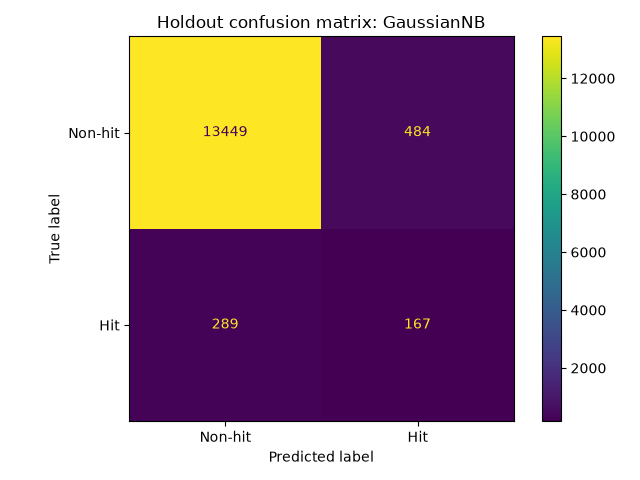

In [3]:
import json
selection = json.loads(ctx.path('metrics', 'classification_selection.json').read_text())
print('Chosen using training CV:', selection['model'])
display(Image(filename=str(ctx.path('plots', 'classification_confusion_matrix.png'))))

Read hit precision (how many shortlisted songs are hits), hit recall (how many real hits are found), F1 and average precision alongside accuracy. Confusion matrix rows are actual labels; columns are predicted labels. Every saved Joblib artifact contains all required preprocessing.